## PageRank

#### Importing packages

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt

#### Power method modiefied for the PageRank

In [2]:
def pagerank_power_method(A, m=0.15, tol = 1e-12, maxIter=10000):
    n = A.shape[0]
    S = np.ones((n,n)) / n
    v = np.ones(n) / n
    col_sums = A.sum(axis=0)
    dangling = (col_sums == 0)
    A[:, dangling] = 1 / n

    flag = False
    k = 0
    M = (1-m)*A + m*S
    while k < maxIter and not flag:
        w = M@v
        w = w / np.sum(w)
        if np.linalg.norm(w - v, 1) < tol:
            flag = True
        v = w
        k += 1

    order = np.argsort(-v) 
    order = order + 1
    v_sorted = v[order-1]
    return v_sorted, flag, k, order,M,w

#### Application to Fig. 2.1

In [3]:
A_fig21 = np.array([
    [0,   0,   1,   1/2],
    [1/3, 0,   0,   0  ],
    [1/3, 1/2, 0,   1/2],
    [1/3, 1/2, 0,   0  ]
])
v1,flag1,k1,order1,M1,w1 = pagerank_power_method(A_fig21) #order if I want a list of indexes (adding 1 if I want the pages' indexes considering that python starts from 0)
A21 = pd.DataFrame(v1, index = order1,columns = ['Eigenvector components'])
display(A21)
print("Number of iterations: ",k1)

,Eigenvector components
1,0.368151
3,0.287962
4,0.202078
2,0.141809


Number of iterations:  36


#### Application to Fig. 2.2

In [4]:
A_fig22 = np.array([
    [0,   1,   0,   0,   0],
    [1,   0,   0,   0,   0],
    [0,   0,   0,   1, 1/2],
    [0,   0,   1,   0,  1/2],
    [0,   0,   0,   0,   0]
])
v2,flag2,k2,order2,M2,w2 = pagerank_power_method(A_fig22)
A22 = pd.DataFrame(v2, index = order2,columns = ['Eigenvector components'])
display(A22)
print("Number of iterations: ",k2)

,Eigenvector components
4,0.285
3,0.285
2,0.200
1,0.200
5,0.030


Number of iterations:  2


#### Importing the dataset

In [5]:
with open('hollins.dat','r') as f:
    first_line = f.readline().strip().split()

n_nodes = int(first_line[0])
n_edges = int(first_line[1])

print("Nodes:", n_nodes, "Edges:", n_edges)


df_nodes = pd.read_csv(
    'hollins.dat',
    sep=r"\s+", header=None, names=["id", "url"],
    nrows=n_nodes+1,        # +1 because we have an offset line 
)

df_nodes = df_nodes.iloc[1:]   # to remove the empty line
display(df_nodes.head())


df_edges = pd.read_csv(
    'hollins.dat',
    sep=r"\s+", header=None, names=["from","to"],
    skiprows=n_nodes+1       # skips header + nodes
)
df_edges.head()

Nodes: 6012 Edges: 23875


,id,url
1,1,http://www1.hollins.edu/
2,2,http://www.hollins.edu/
3,3,http://www1.hollins.edu/Docs/CompTech/Network/...
4,4,http://www1.hollins.edu/Docs/Forms/GetForms.htm
5,5,http://www1.hollins.edu/Docs/misc/travel.htm


,from,to
0,1,2
1,8,2
2,16,2
3,18,2
4,20,2


#### Creation of the link matrix

In [6]:
A = np.zeros((n_nodes, n_nodes))
outdeg = df_edges.groupby("from").size().to_dict()

for idx,row in df_edges.iterrows():
    j = row["from"] - 1   # file indexes start from 1 
    i = row["to"] - 1
    A[i, j] = 1 / outdeg[row["from"]]

colsum = np.sum(A, axis = 0)
dangling_n = np.sum(colsum == 0)
print("Dangling nodes: ",dangling_n)

v,flag,k,order,M,w = pagerank_power_method(A)
print("Number of iterations: ",k)

Dangling nodes:  3189
Number of iterations:  138


#### Application of PageRank to the dataset

In [7]:
df_results = pd.DataFrame({
    "Page": order,
    "Rank": v,
    "URL": df_nodes["url"].iloc[order-1]
})

df_results = df_results.reset_index(drop=True)
print(df_results.head(20).to_string(index=False))

 Page     Rank                                                                        URL
    2 0.019879                                                    http://www.hollins.edu/
   37 0.009288                          http://www.hollins.edu/admissions/visit/visit.htm
   38 0.008610                                http://www.hollins.edu/about/about_tour.htm
   61 0.008065                                    http://www.hollins.edu/htdig/index.html
   52 0.008027            http://www.hollins.edu/admissions/info-request/info-request.cfm
   43 0.007165                          http://www.hollins.edu/admissions/apply/apply.htm
  425 0.006583            http://www.hollins.edu/academics/library/resources/web_linx.htm
   27 0.005989                           http://www.hollins.edu/admissions/admissions.htm
   28 0.005572                             http://www.hollins.edu/academics/academics.htm
 4023 0.004452  http://www1.hollins.edu/faculty/saloweyca/clas%20395/Sculpture/sld001.htm
   29 0.00

## Exercise 14

In [8]:
A_14 = np.array([
    [0,   0,   1/2,   1/2 ,0],
    [1/3, 0,   0,   0,   0  ],
    [1/3, 1/2, 0,   1/2, 1],
    [1/3, 1/2, 0,   0,  0  ],
    [0,   0   ,1/2, 0,  0]
])
m = 0.15
v3,flag3,k3,order3,M3,q3 = pagerank_power_method(A_14,m)
A14 = pd.DataFrame(v3, index = order3,columns = ['Eigenvector components'])
display(A14)
#Second largest eigenvalue
eigvals = np.linalg.eigvals(M3)
eigvals_abs = np.abs(eigvals)
eigvals_sorted = np.sort(eigvals_abs)
lambda2 = eigvals_sorted[-2]
print("λ2 = ",lambda2)

,Eigenvector components
3,0.348894
1,0.237141
5,0.178280
4,0.138496
2,0.097190


λ2 =  0.6112685063651938


#### Results

,k,L1_Norm,Convergence_Ratio
0,1,2.218875e-01,0.596361
1,5,3.408111e-02,0.571927
2,10,2.799481e-03,0.614363
3,50,8.129261e-12,0.643294


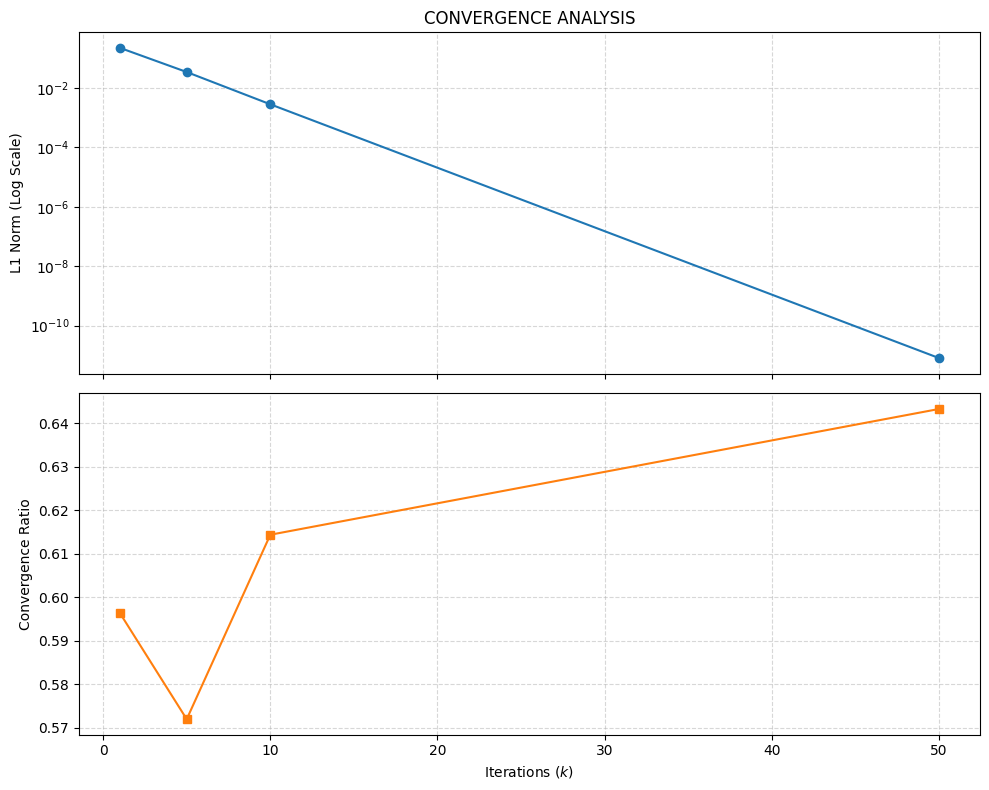

In [9]:
def Mk_times_x0(M, k, x0):
    v = x0.copy()
    i=0
    while i<k:
        v = M @ v
        v = v / np.sum(v) # normalization
        i+=1
    return v
x0 = np.ones(5)
x0 = x0 / np.sum(x0)

# List to store results
convergence_data = []

k_values = [1, 5, 10, 50]
for i in k_values:
    v_k = Mk_times_x0(M3, i, x0)
    v_k1 = Mk_times_x0(M3, i-1, x0)
    
    norm = np.linalg.norm(v_k - q3, 1)
    norm_k1 = np.linalg.norm(v_k1 - q3, 1)
    
    ratio = norm / norm_k1
    
    convergence_data.append({
        'k': i,
        'L1_Norm': norm,
        'Convergence_Ratio': ratio
    })


df_convergence = pd.DataFrame(convergence_data)
display(df_convergence)


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

ax1.plot(df_convergence['k'], df_convergence['L1_Norm'], marker='o', color='tab:blue')
ax1.set_yscale('log') # log scale for exponential decay
ax1.set_ylabel('L1 Norm (Log Scale)')
ax1.set_title('CONVERGENCE ANALYSIS')
ax1.grid(True, which="both", linestyle='--', alpha=0.5)

ax2.plot(df_convergence['k'], df_convergence['Convergence_Ratio'], marker='s', color='tab:orange')
ax2.set_xlabel('Iterations ($k$)')
ax2.set_ylabel('Convergence Ratio')
ax2.grid(True, linestyle='--', alpha=0.5)


plt.tight_layout()

#### Convergence analysis for $k \in [0,50]$

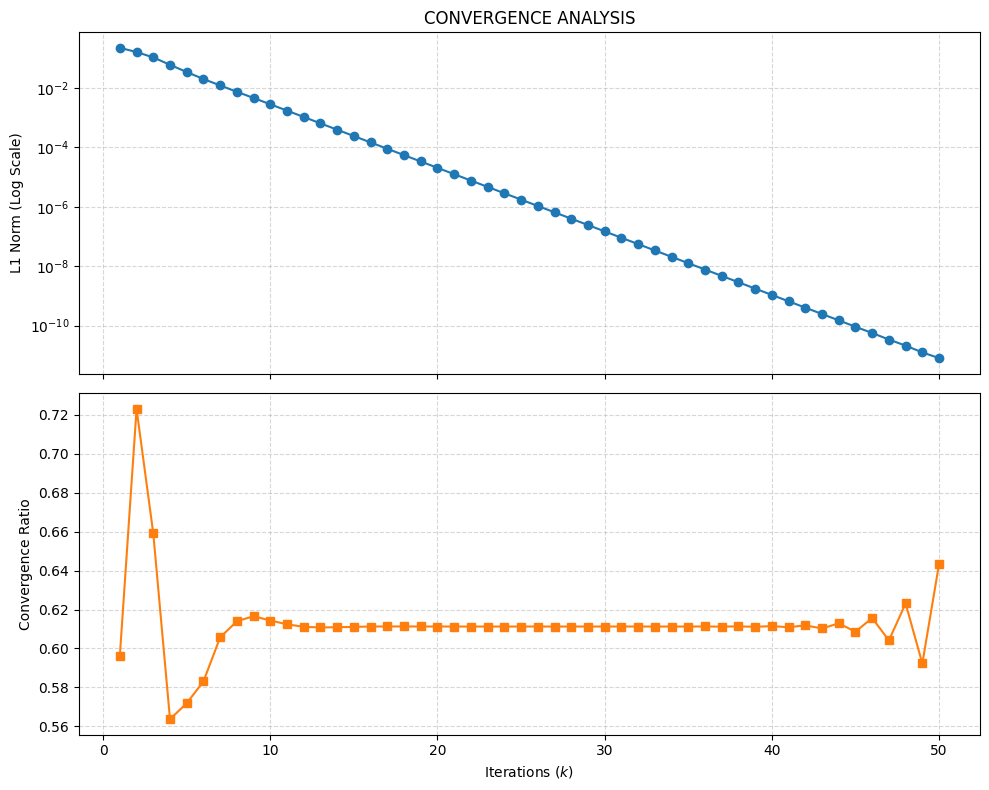

In [10]:
convergence_data2 = []
k_values = range(1,51)
for i in k_values:
    v_k = Mk_times_x0(M3, i, x0)
    v_k1 = Mk_times_x0(M3, i-1, x0)
    
    norm = np.linalg.norm(v_k - q3, 1)
    norm_k1 = np.linalg.norm(v_k1 - q3, 1)
    
    ratio = norm / norm_k1

    convergence_data2.append({
        'k': i,
        'L1_Norm': norm,
        'Convergence_Ratio': ratio
    })
df_convergence2 = pd.DataFrame(convergence_data2)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

ax1.plot(df_convergence2['k'], df_convergence2['L1_Norm'], marker='o', color='tab:blue')
ax1.set_yscale('log')
ax1.set_ylabel('L1 Norm (Log Scale)')
ax1.set_title('CONVERGENCE ANALYSIS')
ax1.grid(True, which="both", linestyle='--', alpha=0.5)


ax2.plot(df_convergence2['k'], df_convergence2['Convergence_Ratio'], marker='s', color='tab:orange')
ax2.set_xlabel('Iterations ($k$)')
ax2.set_ylabel('Convergence Ratio')
ax2.grid(True, linestyle='--', alpha=0.5)


plt.tight_layout()

#### Check

In [11]:
min_per_col = np.min(M3, axis=0)
values = np.abs(1 - 2 * min_per_col)
c = np.max(values)
print('c =',c)
r=[1,0,-1,1,-1]
a=np.linalg.norm(M3@r,1)
b=c*np.linalg.norm(r,1)
print('a =', a,'b = ',b)

c = 0.94
a = 1.1333333333333333 b =  3.76
